# Ejercicio 3 — SVD, pseudoinversa y truncamiento

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from comun import cargar_datos

datos = cargar_datos()
lam, A, edades, b, b_ideal, x_real = (
    datos[k] for k in ("lam", "A", "edades", "b", "b_ideal", "x_real")
)

FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

eta = np.linalg.norm(b - b_ideal)

## 1. Descomposición en valores singulares

Se calcula la SVD reducida $A = U\Sigma V^\top$, con $U\in\mathbb{R}^{4300\times15}$ de columnas ortonormales, $\Sigma = \operatorname{diag}(\sigma_1,\dots,\sigma_{15})$ con $\sigma_1\ge\dots\ge\sigma_{15}>0$, y $V\in\mathbb{R}^{15\times15}$ ortogonal. Se verifica que $U\Sigma V^\top$ reconstruye $A$ y que $U$ y $V$ son ortonormales a precisión de máquina.

- Los 15 valores singulares son positivos: $A$ tiene **rango completo**.
- Caen **cuatro órdenes de magnitud**, de $\sigma_1\approx241$ a $\sigma_{15}\approx0{,}040$, y $\kappa_2(A) = \sigma_1/\sigma_{15}\approx6066$. Es el mismo valor que en el Ej. 2.
- Hay un **codo claro después de $\sigma_4$**: los cuatro primeros concentran casi toda la "energía" de $A$, y de $\sigma_5$ en adelante la caída es lenta (de 0,66 a 0,04). Las columnas de $A$ están cerca de un subespacio de dimensión ~4, consistente con la alta correlación entre SSP vista en el Ej. 1.

Forma de A: (4300, 15)
Forma de U: (4300, 15) | forma de s: (15,) | forma de Vt: (15, 15)
Valores singulares:
  σ_ 1 = 2.4118e+02
  σ_ 2 = 5.5180e+01
  σ_ 3 = 8.2031e+00
  σ_ 4 = 3.0729e+00
  σ_ 5 = 6.5858e-01
  σ_ 6 = 4.2879e-01
  σ_ 7 = 3.2382e-01
  σ_ 8 = 2.5067e-01
  σ_ 9 = 2.0894e-01
  σ_10 = 1.6066e-01
  σ_11 = 1.3095e-01
  σ_12 = 9.1740e-02
  σ_13 = 6.7652e-02
  σ_14 = 5.9931e-02
  σ_15 = 3.9761e-02
s[0] / s[-1] = 6065.839028354766
||A - U diag(s) Vt|| / ||A|| = 1.1585899609757884e-15
||U.T @ U - I|| = 4.026907142789776e-15
||Vt @ Vt.T - I|| = 4.917716359388689e-15


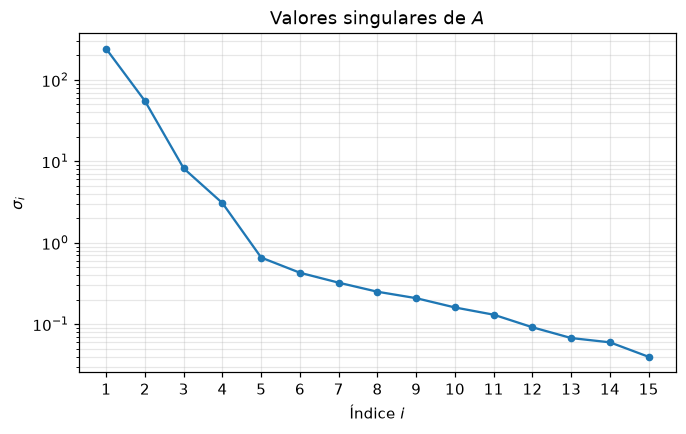

In [2]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
n = A.shape[1]

print("Forma de A:", A.shape)
print("Forma de U:", U.shape, "| forma de s:", s.shape, "| forma de Vt:", Vt.shape)
print("Valores singulares:")
for i, sv in enumerate(s, start=1):
    print(f"  σ_{i:2d} = {sv:.4e}")
print("s[0] / s[-1] =", s[0] / s[-1])
print("||A - U diag(s) Vt|| / ||A|| =", np.linalg.norm(A - U @ np.diag(s) @ Vt) / np.linalg.norm(A))
print("||U.T @ U - I|| =", np.linalg.norm(U.T @ U - np.eye(n)))
print("||Vt @ Vt.T - I|| =", np.linalg.norm(Vt @ Vt.T - np.eye(n)))

indices = np.arange(1, n + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(indices, s, "o-", markersize=4)
ax.set_xlabel(r"Índice $i$")
ax.set_ylabel(r"$\sigma_i$")
ax.set_xticks(indices)
ax.grid(True, which="both", alpha=0.3)
ax.set_title(r"Valores singulares de $A$")
fig.savefig(FIG / "01_valores_singulares.png")
plt.show()

## 2. Pseudoinversa y solución

La pseudoinversa de Moore–Penrose se construye a partir de la SVD como

$$A^{+} = V\Sigma^{-1}U^\top, \qquad x_{+} = A^{+}b = \sum_{i=1}^{15}\frac{u_i^\top b}{\sigma_i}\,v_i .$$

**Resultado:** $x_{+}$ coincide con $x_{LS}$ del Ej. 2 a precisión de máquina (diferencia relativa $\sim5\times10^{-13}$). Tiene el mismo error relativo (17,6 %) y el mismo residuo.

**Justificación.** Como $\operatorname{rg}A = 15$, $A^\top A = V\Sigma^2V^\top$ es invertible y

$$(A^\top A)^{-1}A^\top = V\Sigma^{-2}V^\top\,V\Sigma U^\top = V\Sigma^{-1}U^\top = A^{+}.$$

Es decir, $A^{+}b$ es exactamente la solución de las ecuaciones normales, que es la única solución de cuadrados mínimos. Se verifica numéricamente: $A^{+} = (A^\top A)^{-1}A^\top$, $A^{+}A = I_{15}$ y la construcción coincide con `np.linalg.pinv`. Cambia el algoritmo, no el problema: con rango completo, la pseudoinversa no aporta nada nuevo **mientras se usen todas las componentes**.

La expresión en suma explica por qué esa solución es sensible al ruido. Con $b = b_{ideal} + e$, cada término trae una parte $\frac{u_i^\top e}{\sigma_i}v_i$. Las proyecciones $u_i^\top e$ del ruido blanco tienen todas un tamaño similar ($\sim\sigma_{ruido}\approx2\times10^{-3}$), pero se dividen por $\sigma_i$, que llega a $0{,}04$. Los términos con $\sigma_i$ chico **amplifican el ruido** hasta ~25 veces.

In [3]:
A_pinv = Vt.T @ np.diag(1 / s) @ U.T
x_pinv = A_pinv @ b
x_ls = np.linalg.lstsq(A, b, rcond=None)[0]

print("||x_pinv - x_LS|| / ||x_LS|| =", np.linalg.norm(x_pinv - x_ls) / np.linalg.norm(x_ls))
print("||A+ - pinv(A)|| / ||pinv(A)|| =",
      np.linalg.norm(A_pinv - np.linalg.pinv(A)) / np.linalg.norm(np.linalg.pinv(A)))
print("||A+ - (A^T A)^-1 A^T|| / ||A+|| =",
      np.linalg.norm(A_pinv - np.linalg.solve(A.T @ A, A.T)) / np.linalg.norm(A_pinv))
print("||A+ A - I|| =", np.linalg.norm(A_pinv @ A - np.eye(n)))
print("||x_pinv - x_real|| / ||x_real|| =", np.linalg.norm(x_pinv - x_real) / np.linalg.norm(x_real))
print("||A x_pinv - b|| =", np.linalg.norm(A @ x_pinv - b))

||x_pinv - x_LS|| / ||x_LS|| = 4.969365017393329e-13
||A+ - pinv(A)|| / ||pinv(A)|| = 1.0489885581922969e-16
||A+ - (A^T A)^-1 A^T|| / ||A+|| = 5.267102459122145e-10
||A+ A - I|| = 4.708194211777025e-13
||x_pinv - x_real|| / ||x_real|| = 0.17577017387016097
||A x_pinv - b|| = 0.1143892146968779


## 3. Aproximación de rango $k$

La aproximación de rango $k$ conserva las primeras $k$ componentes de rango uno,

$$A_k = \sum_{i=1}^{k}\sigma_i\,u_i v_i^\top, \qquad x_k = A_k^{+}b = \sum_{i=1}^{k}\frac{u_i^\top b}{\sigma_i}\,v_i ,$$

que es la **SVD truncada** (TSVD). Por el teorema de Eckart–Young, $A_k$ es la mejor aproximación de rango $k$ en norma 2, con $\|A-A_k\|_2 = \sigma_{k+1}$. Se verifica numéricamente para $k=5$, y también que la fórmula de $x_k$ coincide con `pinv(A_k) b`.

Truncar equivale a **descartar los términos con $\sigma_i$ chico**, que son justamente los que amplifican el ruido.

In [4]:
X = np.empty((n, n))  # fila k-1 = x_k
filas = []
for k in range(1, n + 1):
    x_k = Vt[:k].T @ ((U[:, :k].T @ b) / s[:k])
    X[k - 1] = x_k
    r_k = np.linalg.norm(A @ x_k - b)
    filas.append({
        "k": k,
        "‖A−A_k‖₂": s[k] if k < n else 0.0,
        "‖x_k − x_real‖/‖x_real‖": np.linalg.norm(x_k - x_real) / np.linalg.norm(x_real),
        "‖A x_k − b‖₂": r_k,
        "‖A x_k − b‖₂/η": r_k / eta,
        "‖x_k‖₂": np.linalg.norm(x_k),
        "Σ x_k": x_k.sum(),
        "# componentes negativas": int(np.sum(x_k < 0)),
    })

# Verificación para k = 5: x_k = pinv(A_k) b y ||A - A_k||_2 = s[k]
k0 = 5
A_5 = U[:, :k0] @ np.diag(s[:k0]) @ Vt[:k0]
x_5_pinv = np.linalg.pinv(A_5, rcond=1e-12) @ b
print("k = 5: ||x_5 - pinv(A_5, rcond=1e-12) b|| / ||pinv(A_5, rcond=1e-12) b|| =",
      np.linalg.norm(X[k0 - 1] - x_5_pinv) / np.linalg.norm(x_5_pinv))
print("k = 5: ||A - A_5||_2 =", np.linalg.norm(A - A_5, 2), "| s[5] (σ_6) =", s[k0])

pd.set_option("display.float_format", "{:.6g}".format)
tabla_k = pd.DataFrame(filas)
errores_x = tabla_k["‖x_k − x_real‖/‖x_real‖"]
k_min = int(tabla_k.loc[errores_x.idxmin(), "k"])
print(f"k con error relativo mínimo en x: k = {k_min}, error = {errores_x.min():.6g}")
tabla_k

k = 5: ||x_5 - pinv(A_5, rcond=1e-12) b|| / ||pinv(A_5, rcond=1e-12) b|| = 3.52344693618595e-14
k = 5: ||A - A_5||_2 = 0.4287851799490507 | s[5] (σ_6) = 0.42878517994905013
k con error relativo mínimo en x: k = 11, error = 0.0646497


,k,‖A−A_k‖₂,‖x_k − x_real‖/‖x_real‖,‖A x_k − b‖₂,‖A x_k − b‖₂/η,‖x_k‖₂,Σ x_k,# componentes negativas
0,1,55.18,0.379128,3.0128,26.2761,0.25273,0.970003,0
1,2,8.20308,0.324225,0.532534,4.64448,0.25838,0.997838,0
2,3,3.07289,0.240243,0.207599,1.81057,0.265206,0.998863,0
3,4,0.658583,0.13048,0.11661,1.01701,0.271032,0.999897,0
4,5,0.428785,0.0720088,0.114647,0.999895,0.272956,1.00005,0
5,6,0.323825,0.076849,0.114571,0.99923,0.27313,1.00008,0
6,7,0.250674,0.0691177,0.11454,0.998961,0.273253,1.00006,0
7,8,0.208943,0.07663,0.114526,0.998837,0.273348,1.00004,0
8,9,0.160656,0.0665123,0.114472,0.998367,0.273865,1.00001,0
9,10,0.130948,0.064846,0.114442,0.998106,0.274348,1.00003,0


## 4. Cómo varía la solución con $k$

- **Residuo:** $\|Ax_k-b\|$ decrece de forma monótona con $k$ (más componentes ⇒ más grados de libertad). Cae muy rápido hasta $k=4$ y desde $k\approx4$–5 queda **plano en $\approx\eta$**: las componentes 5 a 15 casi no mejoran el ajuste del espectro.
- **Error en $x$:** **no** es monótono.
  - Para $k$ chico ($k\le4$) domina el **error de truncamiento**: faltan componentes que sí contienen señal y la solución sale demasiado "suave" (con $k=2$, casi plana).
  - Para $k$ grande ($k\ge12$) domina el **error por ruido amplificado** ($u_i^\top e/\sigma_i$ con $\sigma_i$ chico) y la solución se deteriora hacia el 17,6 % de cuadrados mínimos.
  - Entre $k=5$ y $k=11$, el error se mantiene en torno al **6,5–8 %**. El mínimo es de 6,5 % en $k=11$, menos de la mitad que con cuadrados mínimos.
- Las barras lo muestran: con $k=2$ la forma no se recupera, con $k=6$ y $k=9$ la composición sigue de cerca a $x_{real}$ en todo el rango de edades, y con $k=12$ y $k=15$ reaparecen las oscilaciones entre edades viejas vecinas (2, 2,8, 4 y 8,9 Gyr) que se vieron en el Ej. 2.
- En todos los casos $\sum x_k\approx1$ y no hay componentes negativas.

**Elección de $k$ sin conocer $x_{real}$.** En un problema real no se puede calcular el error en $x$. Un criterio razonable es el menor $k$ cuyo residuo alcanza el nivel de ruido ($\|Ax_k-b\|\approx\eta$), que acá da $k\approx5$, en coincidencia con el codo de los valores singulares. Con $k=5$ el error es del 7,2 %, muy cerca del mínimo.

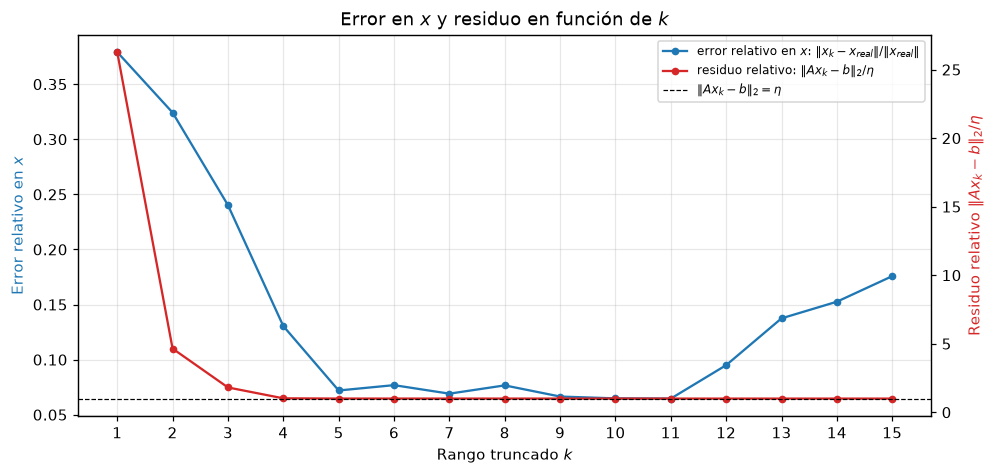

In [5]:
ks = tabla_k["k"].to_numpy()
err_x = tabla_k["‖x_k − x_real‖/‖x_real‖"].to_numpy()
res_rel = tabla_k["‖A x_k − b‖₂/η"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax2 = ax.twinx()

l1, = ax.plot(ks, err_x, "o-", color="C0", markersize=4,
              label=r"error relativo en $x$: $\|x_k - x_{real}\| / \|x_{real}\|$")
l2, = ax2.plot(ks, res_rel, "o-", color="C3", markersize=4,
               label=r"residuo relativo: $\|A x_k - b\|_2 / \eta$")
l3 = ax2.axhline(1, color="k", linestyle="--", linewidth=0.8,
                 label=r"$\|A x_k - b\|_2 = \eta$")

ax.set_xlabel("Rango truncado $k$")
ax.set_ylabel("Error relativo en $x$", color="C0")
ax2.set_ylabel(r"Residuo relativo $\|A x_k - b\|_2 / \eta$", color="C3")
ax.set_xticks(ks)
ax.grid(True, alpha=0.3)
ax.set_title(r"Error en $x$ y residuo en función de $k$")
ax.legend(handles=[l1, l2, l3], loc="best", fontsize=8)

fig.savefig(FIG / "02_error_residuo_k.png")
plt.show()

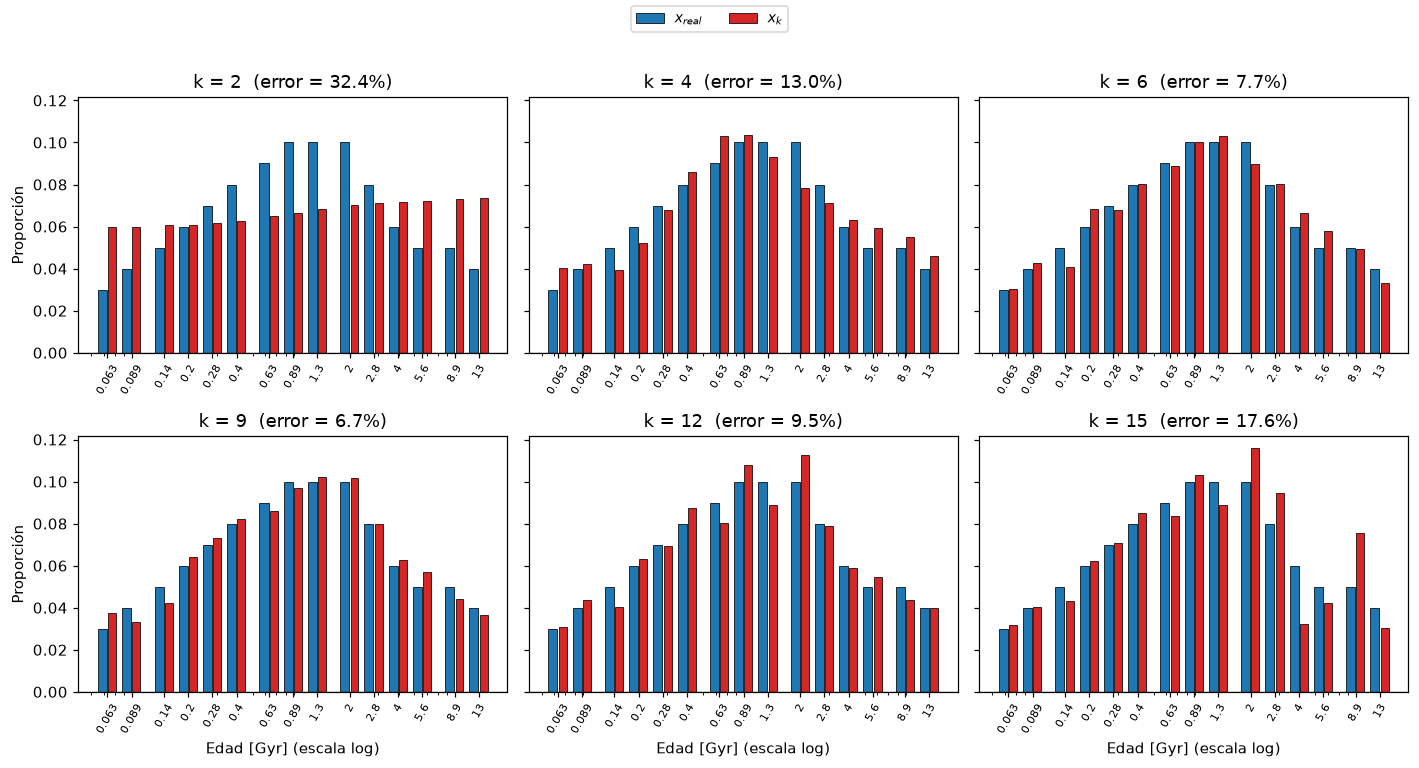

In [6]:
from matplotlib.ticker import NullFormatter

ks_b = [2, 4, 6, 9, 12, 15]
ancho = edades * 0.12

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, k in zip(axes.ravel(), ks_b):
    x_k = X[k - 1]
    err = np.linalg.norm(x_k - x_real) / np.linalg.norm(x_real)
    ax.set_xscale("log")
    ax.bar(edades * 10 ** (-0.03), x_real, width=ancho, color="C0", edgecolor="k",
           linewidth=0.5, label=r"$x_{real}$")
    ax.bar(edades * 10 ** (+0.03), x_k, width=ancho, color="C3", edgecolor="k",
           linewidth=0.5, label=r"$x_k$")
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(f"k = {k}  (error = {err:.1%})")
    ax.set_xticks(edades)
    ax.set_xticklabels([f"{ed:.2g}" for ed in edades], rotation=60, fontsize=7)
    ax.xaxis.set_minor_formatter(NullFormatter())

for ax in axes[1]:
    ax.set_xlabel("Edad [Gyr] (escala log)")
for ax in axes[:, 0]:
    ax.set_ylabel("Proporción")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))

fig.savefig(FIG / "03_xk_varios_k.png")
plt.show()

## Conclusiones del ejercicio 3

1. $A$ tiene rango completo, pero sus valores singulares caen cuatro órdenes de magnitud ($\kappa\approx6\times10^3$), con un codo en $\sigma_4$.
2. La pseudoinversa $A^{+} = V\Sigma^{-1}U^\top$ da **exactamente la misma solución que cuadrados mínimos**, porque con rango completo $A^{+} = (A^\top A)^{-1}A^\top$.
3. Escrita como $\sum_i (u_i^\top b/\sigma_i)\,v_i$, la solución muestra el origen del problema: los $\sigma_i$ chicos amplifican el ruido.
4. Truncar a rango $k$ (TSVD) elimina esos términos. El residuo prácticamente no cambia para $k\ge5$, pero el error en $x$ baja del 17,6 % a ~6,5–7 %. Hay un compromiso entre error de truncamiento ($k$ chico) y ruido amplificado ($k$ grande).
5. Elegir $k$ por el nivel de ruido ($k\approx5$) da un resultado casi óptimo sin usar $x_{real}$. Esto motiva la regularización de Tikhonov del Ej. 4, que en lugar de cortar las componentes las atenúa en forma gradual.